## **Airplane Satisfaction Project**

In this notebook I will be using different classification models to predict airplane satisfaction in the *Airplane Satisfaction Kaggle Competition*. I will be doing EDA, feature selection, model training and testing, and then model evaluation. I will be testing 3 different models and seeing which one performs the best: *logistic regression, QDA, and a decision tree*.

In [1]:
#importing all the libriaries I will use later
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


## **Data Examination**

Here is a small look at the dataset I will be using to train my models. As you can see, there are 21 features along with an ID column and satisfaction, which is our response. Of these 21 features, 4 of them are categorical, so we will need to encode them somehow to make them numeric. Looking at the counts of all the quantitative features, the only feature that has missing values is *Arrival Delay in Minutes*. 

In [2]:
#read in the data and inspect
test = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/test.csv")

train = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/train.csv")
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [3]:
train.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.000000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.000000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.372129,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.000000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.500000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.000000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.500000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


## **Encoding and Missing Values**

I will encode all of the categorical values to one binary variable to cut down on predictor amounts, besides Class, which will have an extra variable for *Eco Plus*. The only predictor with missing values is *Arrival Delay in Minutes*, so I will impute this missing data with the median to avoid errors with skew.


In [4]:
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

# One-hot encode the selected categorical columns
train_encoded = pd.get_dummies(
    train, 
    columns=categorical_cols, 
    drop_first=True, 
    dtype=int
)

# Inspect newly generated binary feature columns
encoded_cols = [c for c in train_encoded.columns if any(c.startswith(f"{prefix}_") for prefix in categorical_cols)]
print(train_encoded[encoded_cols].head())

   Gender_Male  Customer Type_disloyal Customer  \
0            0                                0   
1            1                                0   
2            0                                0   
3            1                                0   
4            0                                1   

   Type of Travel_Personal Travel  Class_Eco  Class_Eco Plus  
0                               1          1               0  
1                               0          0               0  
2                               1          1               0  
3                               1          1               0  
4                               0          1               0  


In [5]:
target_col = 'satisfaction'

# Impute 'Arrival Delay in Minutes' with median
median_delay = train_encoded['Arrival Delay in Minutes'].median()
train_encoded['Arrival Delay in Minutes'] = train_encoded['Arrival Delay in Minutes'].fillna(median_delay)

# Ensure boolean values become 1 and 0
train_encoded[target_col] = train_encoded[target_col].astype(int)

## **Correlation**

I want to reduce the number of predictors in my model, so I will test each of their correlations with the response variable. The top 5 predictors will be used in my model.

In [6]:
# Calculate correlations against the target
target_corr = (
    train_encoded.corr(numeric_only=True)[[target_col]]
    .drop(index=target_col)
    .rename(columns={target_col: 'Correlation'})
)

# Sort by absolute strength to highlight both positive and negative relationships
target_corr['Abs_Correlation'] = target_corr['Correlation'].abs()
ranked_correlations = target_corr.sort_values(by='Abs_Correlation', ascending=False)

# Display top 10 features
print(ranked_correlations.drop(columns='Abs_Correlation').head(10))

                                Correlation
Online boarding                    0.559583
Class_Eco                         -0.521053
Type of Travel_Personal Travel    -0.444418
Inflight entertainment             0.430755
Seat comfort                       0.401488
Flight Distance                    0.370038
On-board service                   0.346618
Cleanliness                        0.338853
Leg room service                   0.330116
Inflight wifi service              0.291275


## **Logistic Regression**

In [7]:
#split the data into train and testing
features = ['Online boarding', 'Class_Eco', 'Type of Travel_Personal Travel', 'Inflight entertainment', 'Seat comfort', 'Flight Distance', 'On-board service']
X = train_encoded[features]
y = train_encoded['satisfaction']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [8]:
#Fitting the model
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

## **LR Evaluation**



In [9]:
#Testing the model and printing out metrics
y_pred = model.predict(X_val)
y_pred_proba = model.predict_proba(X_val)[:, 1]

print(f"ROC-AUC Score: {roc_auc_score(y_val, y_pred_proba):.4f}")

ROC-AUC Score: 0.9095


In [10]:
categorical_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

# One-hot encode the selected categorical columns
test_encoded = pd.get_dummies(
    test, 
    columns=categorical_cols, 
    drop_first=True, 
    dtype=int
)

# Impute 'Arrival Delay in Minutes' with median
median_delay = test_encoded['Arrival Delay in Minutes'].median()
test_encoded['Arrival Delay in Minutes'] = test_encoded['Arrival Delay in Minutes'].fillna(median_delay)

# Inspect newly generated binary feature columns
encoded_cols = [c for c in test_encoded.columns if any(c.startswith(f"{prefix}_") for prefix in categorical_cols)]
print(test_encoded[encoded_cols].head())

   Gender_Male  Customer Type_disloyal Customer  \
0            0                                1   
1            1                                0   
2            1                                0   
3            0                                1   
4            1                                0   

   Type of Travel_Personal Travel  Class_Eco  Class_Eco Plus  
0                               0          1               0  
1                               0          1               0  
2                               0          1               0  
3                               0          0               0  
4                               1          0               1  


In [11]:
predictions = model.predict(test_encoded[features])

output = pd.DataFrame({'id': test_encoded.id, 'satisfaction': predictions})
output.to_csv('submission.csv', index=False)

## **QDA**



In [12]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve

target = 'satisfaction'  # Change to 'satisfaction' if not renamed during encoding

drop_cols = [c for c in ['Unnamed: 0', 'id', target] if c in train_encoded.columns]
X_train = train_encoded.drop(columns=drop_cols)
X_test = test_encoded[X_train.columns]  # Ensures identical column order

y_train = train_encoded[target].astype(int)


# Scale features and fit QDA
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

qda = QuadraticDiscriminantAnalysis(reg_param=0.01)
qda.fit(X_train_scaled, y_train)

# Predict on test_encoded
preds = qda.predict(X_test_scaled)
probs = qda.predict_proba(X_test_scaled)[:, 1]

## **QDA Evaluation**



In [13]:
train_probs = qda.predict_proba(X_train_scaled)[:, 1]
train_roc_auc = roc_auc_score(y_train, train_probs)

cv_roc_auc = cross_val_score(qda, X_train_scaled, y_train, cv=5, scoring='roc_auc').mean()

print(f"Training ROC-AUC Score:   {train_roc_auc:.4f}")
print(f"5-Fold CV ROC-AUC Score:  {cv_roc_auc:.4f}")

Training ROC-AUC Score:   0.8974
5-Fold CV ROC-AUC Score:  0.8974


In [14]:
# 1. Predict on the scaled test_encoded features
test_preds = qda.predict(X_test_scaled)

# 2. Retrieve passenger IDs
if 'id' in test_encoded.columns:
    passenger_ids = test_encoded['id']
else:
    passenger_ids = test['id']

# 3. Create the submission
submissionQDA = pd.DataFrame({
    'id': passenger_ids,
    'satisfaction': test_preds
})

# 4. Export to CSV
submissionQDA.to_csv('submissionQDA.csv', index=False)

## **Decision Tree**



In [15]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV

# Select all predictor columns
drop_cols = [c for c in ['Unnamed: 0', 'id', target] if c in train_encoded.columns]
X_train_all = train_encoded.drop(columns=drop_cols)
X_test_all = test_encoded[X_train_all.columns]

# Find the optimal tree depth via 5-fold CV
param_grid = {
    'max_depth': [6, 8, 10, 12, 14],
    'min_samples_leaf': [20, 40, 60, 80, 100]
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid_dt.fit(X_train_all, y_train)

print(f"Best Parameters: {grid_dt.best_params_}")
print(f"Best 5-Fold CV ROC-AUC: {grid_dt.best_score_:.4f}")

Best Parameters: {'max_depth': 14, 'min_samples_leaf': 100}
Best 5-Fold CV ROC-AUC: 0.9537


## **Tree Evaluation**



In [16]:
# max_depth=6 and min_samples_leaf=50 prevent overfitting and smooth probability estimates
dt = DecisionTreeClassifier(max_depth=14, min_samples_leaf=100, random_state=42)
dt.fit(X_train, y_train)

# Calculate ROC-AUC Scores
train_probs = dt.predict_proba(X_train)[:, 1]
train_roc_auc = roc_auc_score(y_train, train_probs)
cv_roc_auc = cross_val_score(dt, X_train, y_train, cv=5, scoring='roc_auc').mean()

print(f"Training ROC-AUC Score:   {train_roc_auc:.4f}")
print(f"5-Fold CV ROC-AUC Score:  {cv_roc_auc:.4f}")

Training ROC-AUC Score:   0.9588
5-Fold CV ROC-AUC Score:  0.9537


Decision Tree Important Predictors:
                          Feature  Importance
                  Online boarding    0.549354
   Type of Travel_Personal Travel    0.154972
            Inflight wifi service    0.121851
           Inflight entertainment    0.048432
                  Checkin service    0.023288
  Customer Type_disloyal Customer    0.021569
                  Flight Distance    0.017524
                 Baggage handling    0.011312
                     Seat comfort    0.009040
                        Class_Eco    0.009027
                      Cleanliness    0.005947
                              Age    0.005907
                    Gate location    0.005725
           Ease of Online booking    0.004385
                 Leg room service    0.003760
                 On-board service    0.003440
                   Food and drink    0.002431
Departure/Arrival time convenient    0.001007
                   Class_Eco Plus    0.000700
         Arrival Delay in Minutes    0.00016

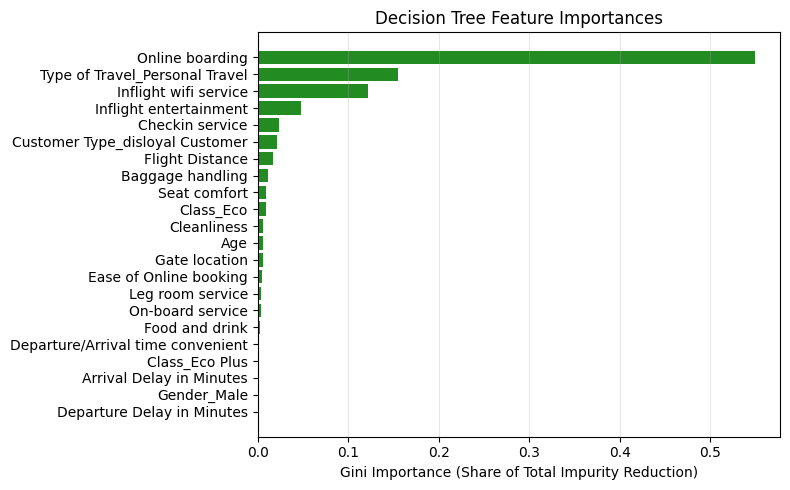

In [17]:
dt_importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': dt.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# 2. Filter out unused features (importance > 0) and display
important_predictors = dt_importances[dt_importances['Importance'] > 0]
print("Decision Tree Important Predictors:")
print(important_predictors.to_string(index=False))

# 3. Pull the top N predictor names into a Python list (e.g., top 5)
top_predictors_list = important_predictors['Feature'].head(5).tolist()
print("\nTop Predictors List:", top_predictors_list)

# 4. Plot Horizontal Bar Chart of Important Predictors
plt.figure(figsize=(8, 5))
plt.barh(
    important_predictors['Feature'][::-1], 
    important_predictors['Importance'][::-1], 
    color='forestgreen'
)
plt.xlabel('Gini Importance (Share of Total Impurity Reduction)')
plt.title('Decision Tree Feature Importances')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
dt_preds = dt.predict(X_test)
passenger_ids = test_encoded['id'] if 'id' in test_encoded.columns else test['id']

submissionDT = pd.DataFrame({
    'id': passenger_ids,
    'satisfaction': dt_preds
})
submissionDT.to_csv('submissionDT.csv', index=False)

## **Reflection**

The model that ended up working the best for me was a decision tree with depth 14 and 100 minimum leaf nodes. This model ended up getting me a place of 3678 in the Kaggle competition and an ROC score of 0.91710. This score was 0.05 better than both the QDA model and the logistic regression model. This could probably be improved even more if I used a Random Forest model or boosting to improve the decision tree. According to the decision tree, the top 5 predictors in determining *airline satisfaction* are *online boarding, personal travel, in-flight wifi, in-flight entertainment,* and *check-in service. Surprisingly, the QDA model performed worse than the logistic regression model.